# Basic CNN — Mendeley Data (PyTorch)

In [89]:
import os
import zipfile
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [90]:
# Mount Google Drive & unzip Mendeley Data dataset
from google.colab import drive
drive.mount("/content/drive")

ZIP_PATH = "/content/drive/MyDrive/CVPR/fungi_dataset.zip"
EXTRACT_DIR = "/content/mendeley_data"

if not os.path.exists(EXTRACT_DIR):
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(EXTRACT_DIR)
print("Extracted to:", EXTRACT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Extracted to: /content/mendeley_data


In [91]:
# Load dataset (auto-detects train/test folders or splits 80/20)
IMG_SIZE = 32
BATCH_SIZE = 32

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
])

test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])

train_dir, test_dir = None, None
for root, dirs, _ in os.walk(EXTRACT_DIR):
    dmap = {d.lower(): d for d in dirs}
    if "train" in dmap and ("test" in dmap or "validation" in dmap or "val" in dmap):
        train_dir = os.path.join(root, dmap["train"])
        test_key = "test" if "test" in dmap else ("validation" if "validation" in dmap else "val")
        test_dir = os.path.join(root, dmap[test_key])
        break

if train_dir and test_dir:
    train_data = datasets.ImageFolder(train_dir, transform=train_transform)
    test_data  = datasets.ImageFolder(test_dir,  transform=test_transform)
    class_names = train_data.classes
else:
    class_root = None
    for root, dirs, _ in os.walk(EXTRACT_DIR):
        valid = [d for d in dirs if not d.startswith((".", "__")) and any(
            f.lower().endswith((".jpg", ".jpeg", ".png")) for f in os.listdir(os.path.join(root, d))
        )]
        if len(valid) >= 2:
            class_root = root
            break
    full_train = datasets.ImageFolder(class_root, transform=train_transform)
    full_test  = datasets.ImageFolder(class_root, transform=test_transform)
    class_names = full_train.classes
    idx = np.arange(len(full_train))
    tr_idx, te_idx = train_test_split(idx, test_size=0.2, random_state=42, stratify=full_train.targets)
    train_data = Subset(full_train, tr_idx)
    test_data  = Subset(full_test, te_idx)

NUM_CLASSES = len(class_names)
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
test_loader  = DataLoader(test_data,  batch_size=BATCH_SIZE, shuffle=False)

print("Classes:", class_names)
print("Number of Classes:", NUM_CLASSES)
print("Train Images:", len(train_data))
print("Test Images :", len(test_data))

Classes: ['H1', 'H2', 'H3', 'H5', 'H6']
Number of Classes: 5
Train Images: 5000
Test Images : 902


In [92]:
# Basic CNN Model
model = nn.Sequential(
    # Conv Block 1: 32x32 -> 32x32 -> 16x16
    nn.Conv2d(3, 32, 3, 1, 1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    # Conv Block 2: 16x16 -> 14x14 -> 7x7
    nn.Conv2d(32, 64, 3, 1, 0),
    nn.ReLU(),
    nn.MaxPool2d(2),

    # Conv Block 3: 7x7 -> 7x7 -> 3x3
    nn.Conv2d(64, 128, 3, 1, 1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    # Classifier
    nn.Flatten(),
    nn.Linear(128 * 3 * 3, 256),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(256, NUM_CLASSES)
).to(device)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print("Total Trainable Parameters:", trainable_params)

Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (7): ReLU()
  (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (9): Flatten(start_dim=1, end_dim=-1)
  (10): Linear(in_features=1152, out_features=256, bias=True)
  (11): ReLU()
  (12): Dropout(p=0.5, inplace=False)
  (13): Linear(in_features=256, out_features=5, bias=True)
)
Total Trainable Parameters: 389701


In [93]:
# Training & Testing Loop
EPOCHS = 20
LR = 0.001

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

train_losses, test_losses = [], []
train_accs, test_accs = [], []
best_acc, best_loss = 0.0, float("inf")

for epoch in range(EPOCHS):
    # Train
    model.train()
    tr_loss, tr_correct, tr_total = 0.0, 0, 0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        out = model(imgs)
        loss = loss_fn(out, labels)
        loss.backward()
        optimizer.step()

        tr_loss += loss.item()
        tr_correct += (out.argmax(1) == labels).sum().item()
        tr_total += labels.size(0)

    # Test
    model.eval()
    te_loss, te_correct, te_total = 0.0, 0, 0
    with torch.no_grad():
        for imgs, labels in test_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            out = model(imgs)
            te_loss += loss_fn(out, labels).item()
            te_correct += (out.argmax(1) == labels).sum().item()
            te_total += labels.size(0)

    tr_loss /= len(train_loader)
    te_loss /= len(test_loader)
    tr_acc = 100.0 * tr_correct / tr_total
    te_acc = 100.0 * te_correct / te_total

    train_losses.append(tr_loss); test_losses.append(te_loss)
    train_accs.append(tr_acc);    test_accs.append(te_acc)

    if te_acc > best_acc:   best_acc = te_acc
    if te_loss < best_loss: best_loss = te_loss

    print(f"Epoch {epoch+1:02d}/{EPOCHS} | Train Loss: {tr_loss:.4f}, Acc: {tr_acc:.2f}% | Test Loss: {te_loss:.4f}, Acc: {te_acc:.2f}%")

Epoch 01/20 | Train Loss: 1.4163, Acc: 36.76% | Test Loss: 1.5370, Acc: 18.74%
Epoch 02/20 | Train Loss: 1.2214, Acc: 47.82% | Test Loss: 0.9994, Acc: 61.86%
Epoch 03/20 | Train Loss: 1.1348, Acc: 52.06% | Test Loss: 0.9620, Acc: 63.41%
Epoch 04/20 | Train Loss: 1.0649, Acc: 55.28% | Test Loss: 0.9363, Acc: 64.86%
Epoch 05/20 | Train Loss: 1.0761, Acc: 55.04% | Test Loss: 0.8681, Acc: 63.53%
Epoch 06/20 | Train Loss: 1.0140, Acc: 57.38% | Test Loss: 1.1170, Acc: 53.44%
Epoch 07/20 | Train Loss: 0.9823, Acc: 59.04% | Test Loss: 0.9203, Acc: 60.64%
Epoch 08/20 | Train Loss: 0.9414, Acc: 60.74% | Test Loss: 1.0163, Acc: 52.00%
Epoch 09/20 | Train Loss: 0.9263, Acc: 61.06% | Test Loss: 1.1635, Acc: 45.90%
Epoch 10/20 | Train Loss: 0.9168, Acc: 61.22% | Test Loss: 0.8485, Acc: 64.63%
Epoch 11/20 | Train Loss: 0.9022, Acc: 63.00% | Test Loss: 0.9899, Acc: 56.65%
Epoch 12/20 | Train Loss: 0.8606, Acc: 64.34% | Test Loss: 0.9113, Acc: 61.86%
Epoch 13/20 | Train Loss: 0.8534, Acc: 65.12% | Test

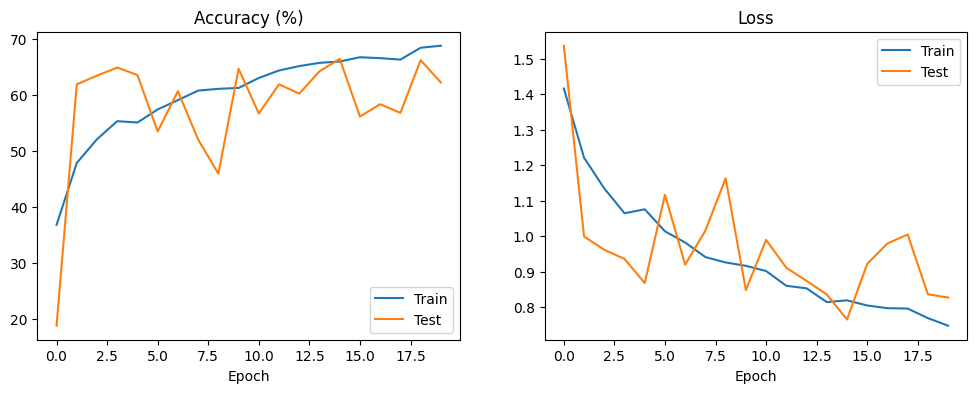

In [94]:
# Accuracy & Loss Plots
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(train_accs, label="Train")
plt.plot(test_accs, label="Test")
plt.title("Accuracy (%)")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_losses, label="Train")
plt.plot(test_losses, label="Test")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.show()

              precision    recall  f1-score   support

          H1       0.75      0.67      0.71       437
          H2       0.39      0.48      0.43       233
          H3       0.56      0.41      0.48        82
          H5       0.72      0.75      0.74        80
          H6       0.77      0.91      0.84        70

    accuracy                           0.62       902
   macro avg       0.64      0.64      0.64       902
weighted avg       0.64      0.62      0.63       902



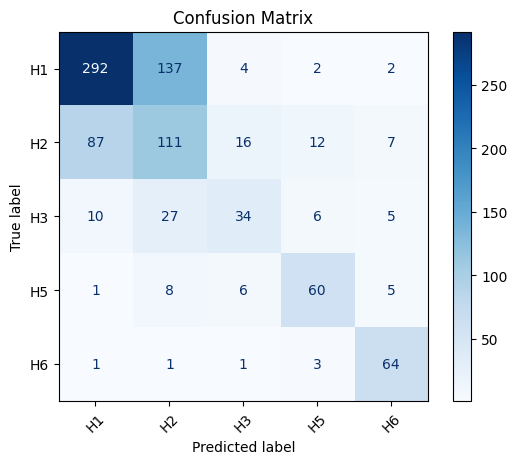

In [95]:
# Confusion Matrix & Classification Report
all_preds, all_labels = [], []
model.eval()
with torch.no_grad():
    for imgs, labels in test_loader:
        out = model(imgs.to(device))
        all_preds.extend(out.argmax(1).cpu().numpy())
        all_labels.extend(labels.numpy())

print(classification_report(all_labels, all_preds, target_names=class_names))

cm = confusion_matrix(all_labels, all_preds)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Confusion Matrix")
plt.show()

In [96]:
# Submission Form Summary
print("Student ID:", "23-52793-2")
print("Student Name:", "Md. Al-Akhiruzzaman Dorpan")
print("Section:", "A")
print("Dataset Name:", "Fungi MultiClass Microscopic Fungi Images")
print("Dataset Link:", "https://data.mendeley.com/datasets/4g9yhrtsy5")
print("Number of Classes:", NUM_CLASSES)
print("Training Images:", len(train_data))
print("Testing Images:", len(test_data))
print(f"Best Accuracy (%): {best_acc:.2f}")
print(f"Best Loss: {best_loss:.4f}")
print("Epochs Trained:", EPOCHS)
print("Regularization: Dropout in Neural Networks")
print("Learning Rate:", LR)
print("Total Trainable Parameters:", trainable_params)

Student ID: 23-52793-2
Student Name: Md. Al-Akhiruzzaman Dorpan
Section: A
Dataset Name: Fungi MultiClass Microscopic Fungi Images
Dataset Link: https://data.mendeley.com/datasets/4g9yhrtsy5
Number of Classes: 5
Training Images: 5000
Testing Images: 902
Best Accuracy (%): 66.41
Best Loss: 0.7655
Epochs Trained: 20
Regularization: Dropout in Neural Networks
Learning Rate: 0.001
Total Trainable Parameters: 389701
